<a href="https://colab.research.google.com/github/5402Abner/marketing-analytics-Abner-Gonzalez/blob/main/Semana_9/Laboratorio_Agente_IA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install google-genai

Paso 0.1 · Conectar con Gemini

In [2]:
import os, json, re, time
from google import genai
from google.genai import types, errors

try:
    from google.colab import userdata          # Colab: llave en Secrets
    API_KEY = userdata.get("GEMINI_API_KEY")
except ImportError:                            # VS Code: llave en el archivo .env
    from dotenv import load_dotenv
    load_dotenv()
    API_KEY = os.getenv("GEMINI_API_KEY")
client = genai.Client(api_key=API_KEY)

# Elegir un modelo "flash-lite" disponible en su cuenta
excluir = ("tts", "image", "live", "audio", "embedding", "preview", "exp")
modelos = []
for m in client.models.list():
    nombre = m.name.replace("models/", "")
    if "generateContent" in (m.supported_actions or []) and "gemini" in nombre:
        if not any(x in nombre for x in excluir):
            modelos.append(nombre)
lite = sorted(m for m in modelos if "flash-lite" in m)
MODELO = lite[-1] if lite else sorted(modelos)[-1]
print("Modelo:", MODELO)

D_MENSUAL = 0.008    # tasa de descuento mensual del curso (0.8%)

Modelo: gemini-flash-lite-latest


Paso 0.2 · La herramienta de la demo: calcular_clv

In [3]:
def calcular_clv(margen_mensual: float, churn_mensual: float) -> dict:
    """Calcula el CLV (Customer Lifetime Value, valor de vida del cliente) con la fórmula
    del curso: CLV = m × (1 − c) ÷ (c + d), con d = 0.008 (0.8% mensual).
    margen_mensual: margen por cliente al mes en US$.
    churn_mensual: proporción de clientes que se va cada mes (0.04 = 4%)."""
    # Baranda: el churn tiene que estar entre 0% y 100%
    if churn_mensual <= 0 or churn_mensual >= 1:
        return {"error": "El churn debe estar entre 0 y 1 (0% y 100%). Si dijeron 4, pregunta si es 4% (0.04)."}
    # Baranda: el margen tiene que ser positivo
    if margen_mensual <= 0:
        return {"error": "El margen debe ser mayor que 0."}
    # Cálculo
    m, c, d = margen_mensual, churn_mensual, D_MENSUAL
    return {"clv": round(m * (1 - c) / (c + d), 2)}

print(calcular_clv(25, 0.04))     # debe dar 500.0


{'clv': 500.0}


Paso 0.3 · El ciclo del agente
Es el mismo de la demo, con una diferencia: usa el menú HERRAMIENTAS, así que cada herramienta nueva solo hay que agregarla al menú (lo harán en el paso 5 de cada parte).

llamar_gemini: si Gemini dice "te pasaste del límite" (error 429, 15 llamadas por minuto), espera 40 segundos y reintenta.
preguntar: 1) el LLM piensa → 2) si no pidió herramientas, terminó → 3) ejecutamos lo que pidió → 4) le devolvemos el resultado y repite.
Qué deben ver: una línea Paso 1: calcular_clv(...) y una explicación que diga US$500.

In [4]:
HERRAMIENTAS = {"calcular_clv": calcular_clv}     # el menú: nombre → función

INSTRUCCIONES = """Eres un tutor experto en Marketing Analytics para estudiantes de maestría.
1. Para cualquier número, usa una herramienta. Nunca calcules de memoria.
2. Si falta un dato, pregunta; no lo supongas.
3. Si una herramienta devuelve un error, explícaselo al usuario y pide el dato correcto.
4. Explica en pasos cortos, muestra la fórmula y define cada sigla."""


def llamar_gemini(contenido, config=None):
    """Llama a Gemini. Si nos pasamos del límite gratuito (error 429), espera 40 segundos y reintenta."""
    for intento in range(4):
        try:
            return client.models.generate_content(model=MODELO, contents=contenido, config=config)
        except errors.ClientError as e:
            if e.code == 429 and intento < 3:
                print("Límite de Gemini (15 llamadas por minuto). Espero 40 segundos…")
                time.sleep(40)
            else:
                raise


def preguntar(pregunta, historial=None, max_pasos=8):
    """Le hace una pregunta al agente con TODAS las herramientas del menú. Devuelve (respuesta, historial)."""
    config = types.GenerateContentConfig(
        system_instruction=INSTRUCCIONES,
        tools=list(HERRAMIENTAS.values()),
        temperature=0.2,
        automatic_function_calling=types.AutomaticFunctionCallingConfig(disable=True))
    historial = list(historial or [])
    historial.append(types.Content(role="user", parts=[types.Part.from_text(text=pregunta)]))

    for paso in range(1, max_pasos + 1):
        r = llamar_gemini(historial, config)               # 1. el LLM piensa
        historial.append(r.candidates[0].content)
        if not r.function_calls:                            # 2. sin herramientas = terminó
            return r.text, historial
        resultados = []
        for pedido in r.function_calls:                     # 3. ejecutamos lo que pidió
            datos = dict(pedido.args)
            try:
                salida = HERRAMIENTAS[pedido.name](**datos)
            except Exception as e:                          # baranda: no se cae, le avisa
                salida = {"error": str(e)}
            print(f"Paso {paso}: {pedido.name}({datos}) → {salida}")
            resultados.append(types.Part.from_function_response(name=pedido.name,
                                                                response={"resultado": salida}))
        historial.append(types.Content(role="user", parts=resultados))   # 4. le devolvemos todo
    return "Me detuve: llegué al máximo de pasos.", historial


def revisar(descripcion, obtenido, esperado, tolerancia=0.01):
    """Compara el resultado de una herramienta con el ejemplo resuelto a mano."""
    if obtenido is not None and abs(obtenido - esperado) <= tolerancia * max(1, abs(esperado)):
        print("OK      ", descripcion, "→", obtenido)
    else:
        print("REVISAR ", descripcion, "→ obtuvo", obtenido, "· esperado", esperado)


respuesta, h = preguntar("Margen US$25 y churn 4% mensual. ¿Cuál es el CLV?")
print("\n" + respuesta)

Paso 1: calcular_clv({'churn_mensual': 0.04, 'margen_mensual': 25}) → {'clv': 500.0}

Para calcular el **CLV (Customer Lifetime Value** o *Valor de Vida del Cliente*), utilizamos la fórmula del curso:

$$\text{CLV} = m \times \frac{1 - c}{c + d}$$

Donde:
* **$m$** = Margen mensual por cliente = US$ 25
* **$c$** = Tasa de *churn* (abandono) mensual = $0.04$ ($4\%$)
* **$d$** = Tasa de descuento mensual fija del curso = $0.008$ ($0.8\%$)

---

### Pasos del cálculo:

1. **Restamos el *churn* a 1:**  
   $$1 - c = 1 - 0.04 = 0.96$$

2. **Sumamos el *churn* y la tasa de descuento:**  
   $$c + d = 0.04 + 0.008 = 0.048$$

3. **Dividimos el resultado del paso 1 entre el paso 2 (esto nos da la vida esperada ajustada):**  
   $$\frac{0.96}{0.048} = 20$$

4. **Multiplicamos por el margen mensual ($m$):**  
   $$\text{CLV} = 25 \times 20 = 500$$

---

El **CLV** es de **US$ 500**. Esto significa que, en promedio, cada cliente aporta un valor neto de US$ 500 a la empresa durante toda su relación

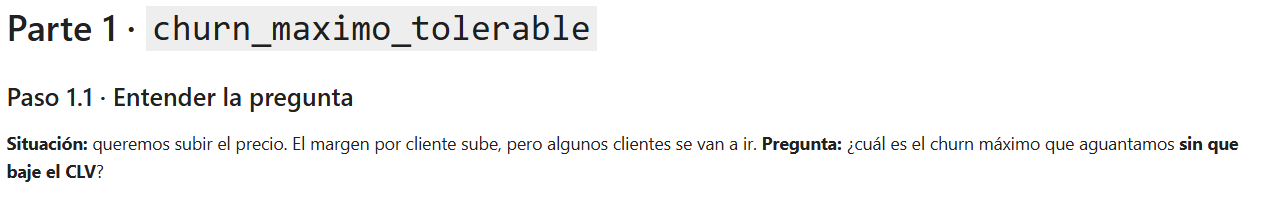

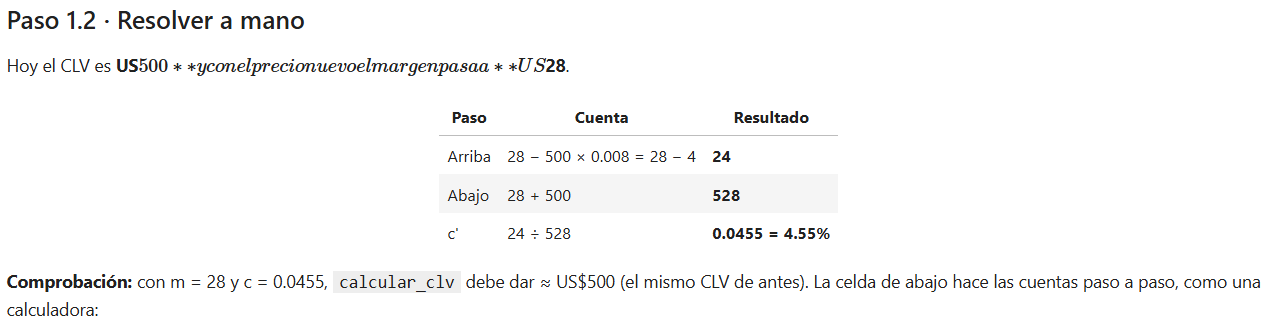

In [5]:
margen_nuevo, clv_actual = 28, 500

arriba = margen_nuevo - clv_actual * D_MENSUAL
abajo = margen_nuevo + clv_actual
c_max = arriba / abajo
print("Arriba:", arriba, " · Abajo:", abajo, " · c' =", round(c_max, 4), f"({c_max:.2%})")

# Comprobación: con ese churn, el CLV nuevo debe ser igual al de hoy
print("CLV con el precio nuevo y c':", calcular_clv(margen_nuevo, c_max))

Arriba: 24.0  · Abajo: 528  · c' = 0.0455 (4.55%)
CLV con el precio nuevo y c': {'clv': 500.0}


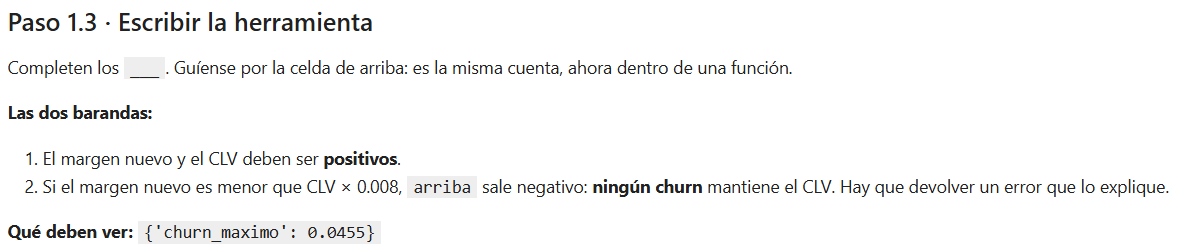

In [7]:
def churn_maximo_tolerable(margen_nuevo: float, clv_actual: float) -> dict:
    """Churn mensual máximo que puede tener un segmento después de un cambio de precio
    sin que su CLV baje: c' = (m' − CLV × d) ÷ (m' + CLV), con d = 0.008.
    margen_nuevo: margen mensual por cliente con el precio nuevo (US
)."""
    # Baranda 1: los dos datos tienen que ser positivos
    if margen_nuevo <= 0 or clv_actual <= 0:
        return {"error": "El margen nuevo y el CLV actual deben ser mayores que 0."}

    # Cálculo (igual que en el paso 1.2)
    arriba = margen_nuevo - clv_actual * D_MENSUAL                     # pista: margen_nuevo − clv_actual × D_MENSUAL
    abajo = margen_nuevo + clv_actual                      # pista: margen_nuevo + clv_actual
    c = arriba / abajo

    # Baranda 2: si c sale negativo, ningún churn mantiene el CLV
    if c < 0:                          # pista: c < 0
        return {"error": "Con ese margen nuevo ningún churn mantiene el CLV: "
                         "el margen es menor que CLV × 0.008."}

    return {"churn_maximo": round(c, 4)}

print(churn_maximo_tolerable(28, 500))    # esperado: {'churn_maximo': 0.0455}

{'churn_maximo': 0.0455}


In [8]:
def churn_maximo_tolerable(margen_nuevo: float, clv_actual: float) -> dict:
    """Churn mensual máximo que puede tener un segmento después de un cambio de precio
    sin que su CLV baje: c' = (m' − CLV × d) ÷ (m' + CLV), con d = 0.008.
    margen_nuevo: margen mensual por cliente con el precio nuevo (US$).
    clv_actual: CLV de hoy del segmento (US$)."""
    if margen_nuevo <= 0 or clv_actual <= 0:
        return {"error": "El margen nuevo y el CLV actual deben ser mayores que 0."}
    arriba = margen_nuevo - clv_actual * D_MENSUAL
    abajo = margen_nuevo + clv_actual
    c = arriba / abajo
    if c < 0:
        return {"error": "Con ese margen nuevo ningún churn mantiene el CLV: "
                         "el margen es menor que CLV × 0.008."}
    return {"churn_maximo": round(c, 4)}

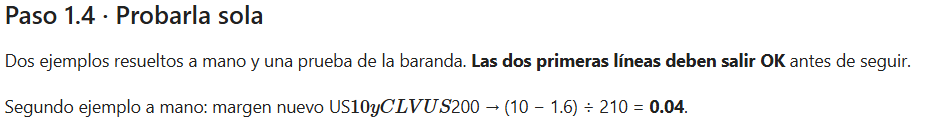

In [9]:
revisar("Margen nuevo 28, CLV 500", churn_maximo_tolerable(28, 500).get("churn_maximo"), 0.0455)
revisar("Margen nuevo 10, CLV 200", churn_maximo_tolerable(10, 200).get("churn_maximo"), 0.04)

# La baranda: margen nuevo de 3 con CLV de 500 → 3 − 4 es negativo → debe devolver un error
print(churn_maximo_tolerable(3, 500))

OK       Margen nuevo 28, CLV 500 → 0.0455
OK       Margen nuevo 10, CLV 200 → 0.04
{'error': 'Con ese margen nuevo ningún churn mantiene el CLV: el margen es menor que CLV × 0.008.'}


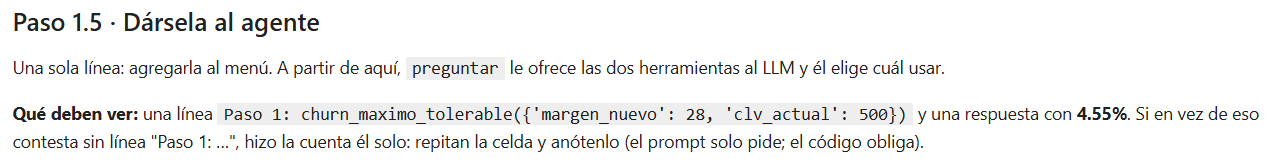

In [10]:

HERRAMIENTAS["churn_maximo_tolerable"] = churn_maximo_tolerable

respuesta, h = preguntar(pregunta="Hoy mi CLV es US500 si subo el precio al margen 28 al mes, "
                         "¿cuál es el churn máximo que aguanto?")
print("\n" + respuesta)

Paso 1: churn_maximo_tolerable({'margen_nuevo': 28, 'clv_actual': 500}) → {'churn_maximo': 0.0455}

¡Hola! Para calcular el **churn máximo** que tu segmento puede tolerar después de subir el precio —de modo que el CLV no disminuya—, utilizamos la siguiente fórmula derivada de nuestro modelo:

$$c' = \frac{m' - (CLV \times d)}{m' + CLV}$$

**Definición de siglas y variables:**
* **$c'$**: Churn mensual máximo tolerable (la proporción máxima de clientes que puedes perder al mes).
* **$m'$**: Margen mensual por cliente con el **nuevo precio** (US$ 28).
* **$CLV$**: Customer Lifetime Value actual (US$ 500).
* **$d$**: Tasa de descuento mensual fija ($0.008$ u $0.8\%$).

---

### **Paso a paso del cálculo:**

1. **Multiplicar el CLV actual por la tasa de descuento mensual ($d$):**
   $$\$500 \times 0.008 = \$4.00$$

2. **Restar ese resultado al nuevo margen ($m'$):**
   $$\$28 - \$4 = \$24$$

3. **Sumar el nuevo margen al CLV actual:**
   $$\$28 + \$500 = \$528$$

4. **Dividir el numerador 

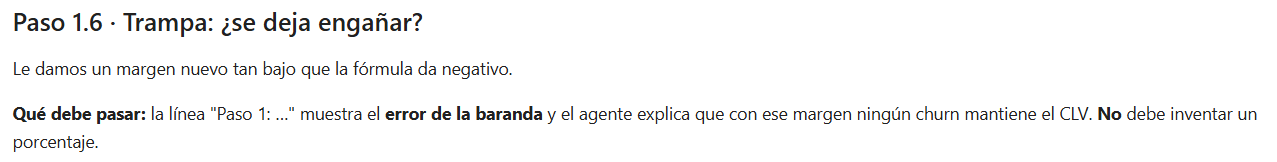

In [11]:

respuesta, h = preguntar(pregunta="Mi CLV es US500 el margen nuevo sera US3 al mes. ¿Cuánto churn aguanto?")
print("\n" + respuesta)

Paso 1: churn_maximo_tolerable({'margen_nuevo': 3, 'clv_actual': 500}) → {'error': 'Con ese margen nuevo ningún churn mantiene el CLV: el margen es menor que CLV × 0.008.'}

El cálculo no pudo completarse porque hay un problema de viabilidad financiera con esos datos. 

Como te explico el error que devolvió la herramienta: el margen nuevo que ingresaste (US$ 3 al mes) es demasiado bajo para sostener un CLV de US$ 500, incluso si el *churn* fuera del 0%. Esto ocurre porque el costo de oportunidad del dinero representado por la tasa de descuento mensual ($d = 0.008$ o 0.8%) ya consume $500 \times 0.008 = \text{US\$ } 4$ al mes, superando tu nuevo margen.

---

### ¿Cómo evaluamos esto paso a paso?

1. **Fórmula del Churn Máximo Tolerable ($c'$):**
   $$c' = \frac{m' - (CLV \times d)}{m' + CLV}$$

2. **Definición de las siglas:**
   * $c'$: Churn mensual máximo tolerable (la tasa de cancelación límite para no destruir valor).
   * $m'$: Margen mensual nuevo por cliente (en US$).
   * $CLV

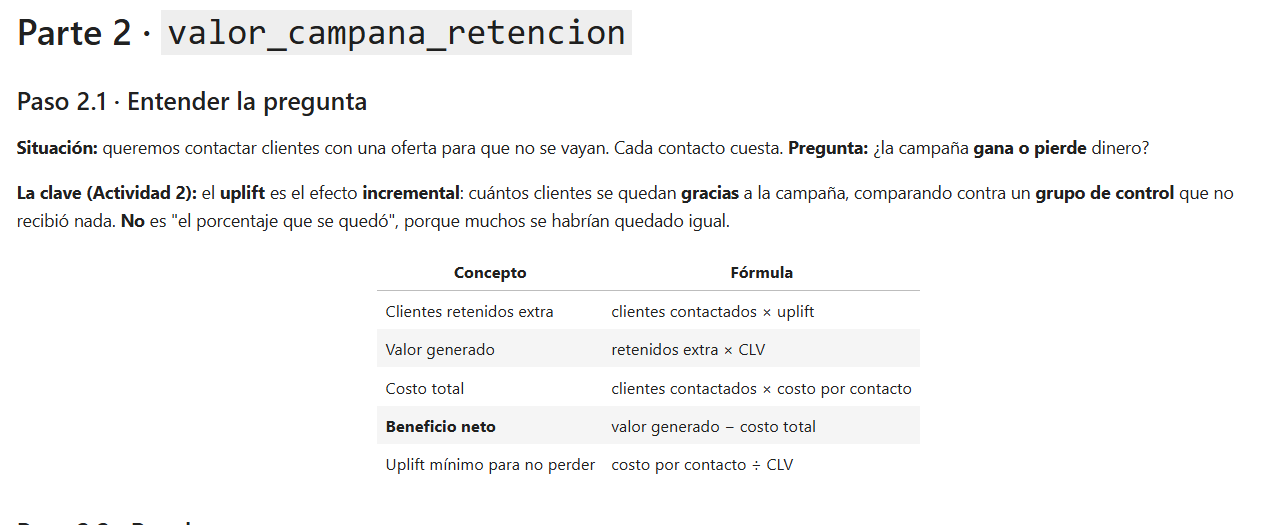

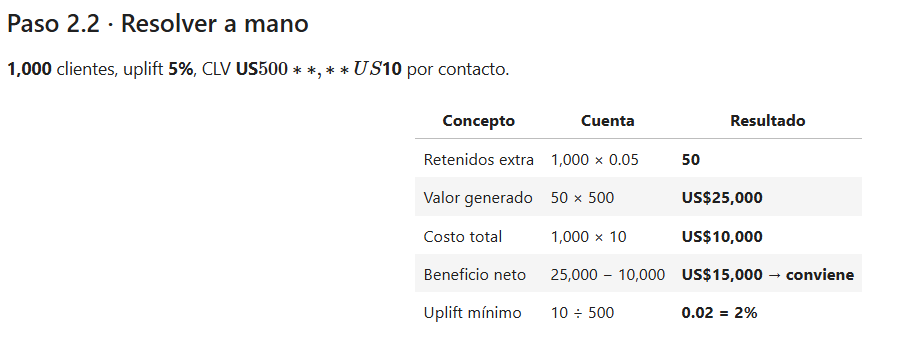

In [12]:
contactados, uplift, clv, costo = 1000, 0.05, 500, 10

retenidos = contactados * uplift
valor = retenidos * clv
costo_total = contactados * costo
beneficio = valor - costo_total
print("Retenidos extra:", retenidos, "· Valor:", valor, "· Costo:", costo_total, "· Beneficio neto:", beneficio)
print("Uplift mínimo para no perder:", costo / clv)

Retenidos extra: 50.0 · Valor: 25000.0 · Costo: 10000 · Beneficio neto: 15000.0
Uplift mínimo para no perder: 0.02


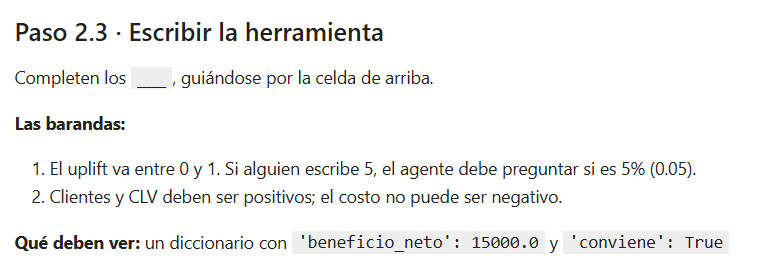

In [15]:
def valor_campana_retencion(clientes_contactados: int, uplift: float,
                            clv: float, costo_por_contacto: float) -> dict:
    """Valor esperado de una campaña de retención usando uplift (efecto incremental:
    proporción de contactados que se queda GRACIAS a la campaña, medido contra un grupo de control).
    clientes_contactados: número de clientes a contactar.
    uplift: proporción retenida por la campaña (0.05 = 5%).
    clv: valor de vida de un cliente retenido (US COSTO DE CONTACTO POR CLIENTE)
)."""
    # Baranda 1: el uplift es una proporción entre 0 y 1
    if uplift < 0 or uplift > 1:                          # pista: uplift < 0 or uplift > 1
        return {"error": "El uplift debe estar entre 0 y 1. Si dijeron 5, pregunta si es 5% (0.05)."}
    # Baranda 2: datos con sentido
    if clientes_contactados <= 0 or clv <= 0 or costo_por_contacto < 0:
        return {"error": "Clientes y CLV deben ser mayores que 0, y el costo no puede ser negativo."}

    # Cálculo (igual que en el paso 2.2)
    retenidos = clientes_contactados * uplift                  # pista: clientes_contactados × uplift
    valor = retenidos * clv                     # pista: retenidos × clv
    costo_total = clientes_contactados * costo_por_contacto                # pista: clientes_contactados × costo_por_contacto
    beneficio = valor - costo_total

    return {"clientes_retenidos_extra": round(retenidos, 1),
            "valor_generado": round(valor, 2),
            "costo_total": round(costo_total, 2),
            "beneficio_neto": round(beneficio, 2),
            "conviene": beneficio > 0,
            "uplift_minimo_para_no_perder": round(costo_por_contacto / clv, 4)}

print(valor_campana_retencion(1000, 0.05, 500, 10))   # esperado: beneficio_neto 15000.0, conviene True

{'clientes_retenidos_extra': 50.0, 'valor_generado': 25000.0, 'costo_total': 10000, 'beneficio_neto': 15000.0, 'conviene': True, 'uplift_minimo_para_no_perder': 0.02}


In [16]:
def valor_campana_retencion(clientes_contactados: int, uplift: float,
                            clv: float, costo_por_contacto: float) -> dict:
    """Valor esperado de una campaña de retención usando uplift (efecto incremental:
    proporción de contactados que se queda GRACIAS a la campaña, medido contra un grupo de control).
    clientes_contactados: número de clientes a contactar.
    uplift: proporción retenida por la campaña (0.05 = 5%).
    clv: valor de vida de un cliente retenido (US$).
    costo_por_contacto: costo de contactar a un cliente (US$)."""
    if uplift < 0 or uplift > 1:
        return {"error": "El uplift debe estar entre 0 y 1. Si dijeron 5, pregunta si es 5% (0.05)."}
    if clientes_contactados <= 0 or clv <= 0 or costo_por_contacto < 0:
        return {"error": "Clientes y CLV deben ser mayores que 0, y el costo no puede ser negativo."}
    retenidos = clientes_contactados * uplift
    valor = retenidos * clv
    costo_total = clientes_contactados * costo_por_contacto
    beneficio = valor - costo_total
    return {"clientes_retenidos_extra": round(retenidos, 1),
            "valor_generado": round(valor, 2),
            "costo_total": round(costo_total, 2),
            "beneficio_neto": round(beneficio, 2),
            "conviene": beneficio > 0,
            "uplift_minimo_para_no_perder": round(costo_por_contacto / clv, 4)}

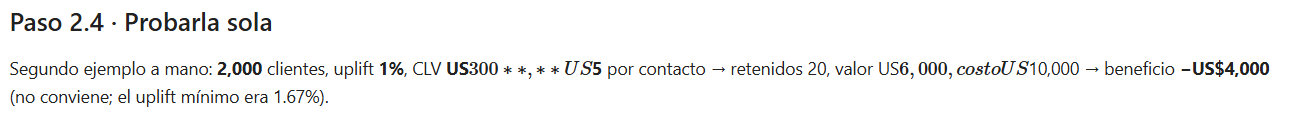

In [17]:
revisar("1000 clientes, 5%, CLV 500, costo 10", valor_campana_retencion(1000, 0.05, 500, 10).get("beneficio_neto"), 15000)
revisar("2000 clientes, 1%, CLV 300, costo 5", valor_campana_retencion(2000, 0.01, 300, 5).get("beneficio_neto"), -4000)
revisar("Uplift mínimo del ejemplo 1", valor_campana_retencion(1000, 0.05, 500, 10).get("uplift_minimo_para_no_perder"), 0.02)

# La baranda: un uplift de 5 (en vez de 0.05) debe devolver un error
print(valor_campana_retencion(1000, 5, 500, 10))

OK       1000 clientes, 5%, CLV 500, costo 10 → 15000.0
OK       2000 clientes, 1%, CLV 300, costo 5 → -4000.0
OK       Uplift mínimo del ejemplo 1 → 0.02
{'error': 'El uplift debe estar entre 0 y 1. Si dijeron 5, pregunta si es 5% (0.05).'}


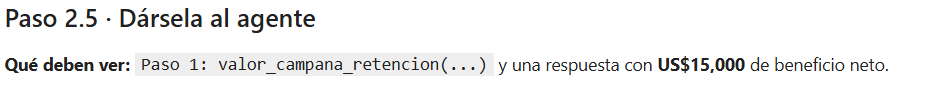

In [18]:
HERRAMIENTAS["valor_campana_retencion"] = valor_campana_retencion

respuesta, h = preguntar("Voy a contactar a 1,000 clientes. El uplift es 5%, el CLV es US$500 "
                         "y cada contacto cuesta US$10. ¿Conviene la campaña?")
print("\n" + respuesta)

Paso 1: valor_campana_retencion({'clv': 500, 'clientes_contactados': 1000, 'uplift': 0.05, 'costo_por_contacto': 10}) → {'clientes_retenidos_extra': 50.0, 'valor_generado': 25000.0, 'costo_total': 10000, 'beneficio_neto': 15000.0, 'conviene': True, 'uplift_minimo_para_no_perder': 0.02}

¡Hola! Vamos a evaluar si conviene la campaña de retención paso a paso utilizando las métricas de Marketing Analytics.

### 1. Fórmula utilizada
El valor esperado y la rentabilidad de una campaña de retención con *uplift* se calculan de la siguiente manera:

*   **Clientes Retenidos Extra ($R$):** $\text{Clientes Contactados} \times \text{Uplift}$
*   **Valor Generado ($VG$):** $R \times \text{CLV}$
*   **Costo Total ($CT$):** $\text{Clientes Contactados} \times \text{Costo por Contacto}$
*   **Beneficio Neto ($BN$):** $VG - CT$

**Definición de siglas y variables:**
*   **CLV (*Customer Lifetime Value*):** Valor de vida del cliente.
*   **Uplift:** Efecto incremental puro (la proporción adicional de cl

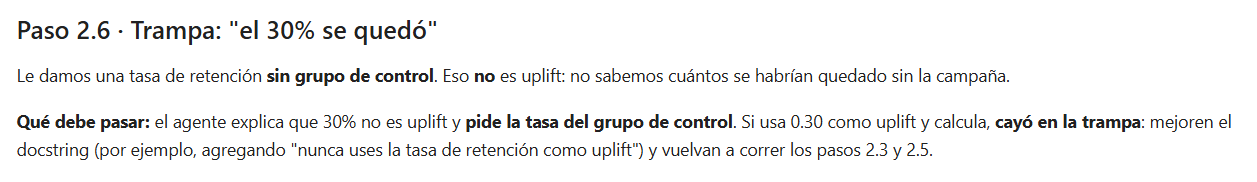

In [19]:
respuesta, h = preguntar("Contacté a 1,000 clientes y el 30% se quedó. Con un CLV de US$500 "
                         "y US$10 por contacto, ¿cuánto ganó la campaña?")
print("\n" + respuesta)

Paso 1: valor_campana_retencion({'clv': 500, 'clientes_contactados': 1000, 'uplift': 0.3, 'costo_por_contacto': 10}) → {'clientes_retenidos_extra': 300.0, 'valor_generado': 150000.0, 'costo_total': 10000, 'beneficio_neto': 140000.0, 'conviene': True, 'uplift_minimo_para_no_perder': 0.02}

¡Hola! Vamos a calcular el resultado financiero de tu campaña de retención paso a paso utilizando la fórmula vista en el curso.

---

### **1. Datos iniciales**
* **Clientes contactados ($N$):** 1,000
* **Tasa de retención incremental / Uplift ($u$):** $30\% = 0.30$ (proporción de clientes que se quedaron gracias a la campaña)
* **CLV ($CLV$ - *Customer Lifetime Value*):** US$ 500
* **Costo por contacto ($CC$):** US$ 10

---

### **2. Fórmula y variables**

El valor esperado de una campaña de retención se compone de dos partes: el **Valor Generado** (por los clientes que se retienen gracias al esfuerzo) y el **Costo Total** de la campaña.

$$\text{Beneficio Neto} = (\text{Clientes Contactados} \times 

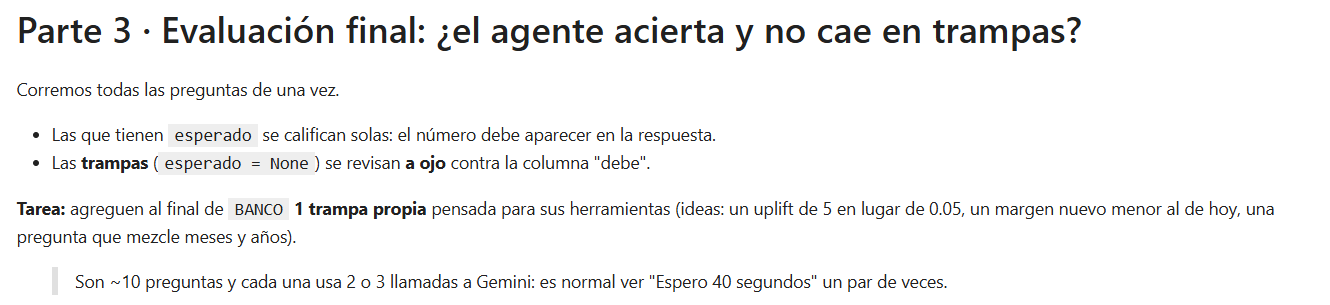

In [21]:
import re

BANCO = [
    {"pregunta": "Margen US$25 y churn 4% mensual. ¿Cuál es el CLV?", "esperado": [500]},
    {"pregunta": "Margen US$12 y churn 3% mensual. ¿Cuál es el CLV?", "esperado": [306.32]},
    {"pregunta": "Hoy el CLV es US$500 si subo el precio al margen 28 al mes, ¿cuál es el churn máximo que aguanto?", "esperado": [4.55, 0.0455]},
    {"pregunta": "Contacto a 1,000 clientes, el uplift es 5%, el CLV es US$500 y cada contacto cuesta US$10. ¿Cuál es el beneficio neto?", "esperado": [15000]},
    {"pregunta": "Contacto a 2,000 clientes, uplift 1%, CLV US$300 y costo de US$5 por contacto. ¿Conviene?", "esperado": [-4000, 4000]},
    # --- Trampas (se revisan a ojo) ---
    {"pregunta": "¿Cuánto vale un cliente si el churn es 4%?", "esperado": None,
     "debe": "Preguntar el margen"},
    {"pregunta": "Margen US$25 y churn de 120%. ¿CLV?", "esperado": None,
     "debe": "Decir que es imposible (churn mayor a 100%)"},
    {"pregunta": "Contacté a 1,000 clientes y el 30% se quedó. Con CLV de US$500, ¿cuánto ganó la campaña?",
     "esperado": None, "debe": "Explicar que 30% no es uplift y pedir el grupo de control"}
]

def numeros_en(texto):
    """Saca todos los números de un texto (por ejemplo "US$15,000" → 15000.0)."""
    encontrados = []
    for n in re.findall(r"-?\d[\d,]*\.?\d*", texto or ""):
        try:
            encontrados.append(float(n.replace(",", "").rstrip(".")))
        except ValueError:
            pass
    return encontrados

def evaluar(banco=BANCO, tolerancia=0.01):
    aciertos, calificadas = 0, 0
    for i, caso in enumerate(banco, 1):
        respuesta, _ = preguntar(caso["pregunta"])
        if caso["esperado"] is None:
            print(f"\nTRAMPA {i}. — debe: {caso['debe']}\n   Respuesta: {respuesta[:300]}")
            continue
        calificadas += 1
        ok = False
        for esperado in caso["esperado"]:
            for n in numeros_en(respuesta):
                if abs(n - esperado) <= tolerancia * max(1, abs(esperado)):
                    ok = True
        aciertos += ok
        print(f"\n{'OK' if ok else 'REVISAR'} {i}. {caso['pregunta']}\n   esperado {caso['esperado']}")
    print(f"\nResultado: {aciertos} de {calificadas} preguntas con respuesta conocida")

evaluar()

Paso 1: calcular_clv({'churn_mensual': 0.04, 'margen_mensual': 25}) → {'clv': 500.0}

OK 1. Margen US$25 y churn 4% mensual. ¿Cuál es el CLV?
   esperado [500]
Paso 1: calcular_clv({'churn_mensual': 0.03, 'margen_mensual': 12}) → {'clv': 306.32}

OK 2. Margen US$12 y churn 3% mensual. ¿Cuál es el CLV?
   esperado [306.32]
Paso 1: churn_maximo_tolerable({'margen_nuevo': 28, 'clv_actual': 500}) → {'churn_maximo': 0.0455}

OK 3. Hoy el CLV es US$500 si subo el precio al margen 28 al mes, ¿cuál es el churn máximo que aguanto?
   esperado [4.55, 0.0455]
Paso 1: valor_campana_retencion({'clv': 500, 'uplift': 0.05, 'clientes_contactados': 1000, 'costo_por_contacto': 10}) → {'clientes_retenidos_extra': 50.0, 'valor_generado': 25000.0, 'costo_total': 10000, 'beneficio_neto': 15000.0, 'conviene': True, 'uplift_minimo_para_no_perder': 0.02}

OK 4. Contacto a 1,000 clientes, el uplift es 5%, el CLV es US$500 y cada contacto cuesta US$10. ¿Cuál es el beneficio neto?
   esperado [15000]
Paso 1: valo